# PM2.5 Regression + Kriging (Street View Predictors)

Regression-kriging for PM2.5 using street-view derived predictors:
GVI, facade area, car count, sky ratio, and road ratio.

In [87]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        has_data = (candidate / "data" / "spatial" / "grid_rectangles.geojson").exists()
        has_src = (candidate / "src").exists()
        if has_data and has_src:
            return candidate
    raise FileNotFoundError("Could not find project root from current notebook path.")


PROJECT_ROOT = find_project_root(Path.cwd())
DATA_DIR = PROJECT_ROOT / "data"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.time_series.series_aligner import align_sensor_series
from src.kriging.ridge_regression import train_ridge, ridge_predict
from src.kriging.variogram_training import fit_variogram_model, plot_variogram_fit, ordinary_kriging_predict

print(f"PROJECT_ROOT: {PROJECT_ROOT}")

PROJECT_ROOT: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis


In [88]:
# Load street view predictor grids
SV_DIR = DATA_DIR / "kriging_street_view"

grid_paths = {
    "gvi":        SV_DIR / "grid_aggregated_gvi.geojson",
    "facades":    SV_DIR / "grid_aggregated_facade_area.geojson",
    "cars":       SV_DIR / "grid_aggregated_n_cars.geojson",
    "sky_ratio":  SV_DIR / "grid_aggregated_sky_ratio.geojson",
    "road_ratio": SV_DIR / "grid_aggregated_road_ratio.geojson",
}

missing = [k for k, p in grid_paths.items() if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing predictor grids: {missing}. Run predictors_export.ipynb first.")

grid_gdfs = {name: gpd.read_file(path) for name, path in grid_paths.items()}
print("Loaded predictors:", list(grid_gdfs.keys()))

Loaded predictors: ['gvi', 'facades', 'cars', 'sky_ratio', 'road_ratio']


In [89]:
# Load Boston sensor series and compute mean PM2.5 between 15:00 and 16:00
SENSORS_DIR = DATA_DIR / "sensors"
sensor_csvs = {
    "Boston Carter Field": SENSORS_DIR / "boston_carter_field" / "boston_carter_field.csv",
    "Boston Gainsborough Parking Garage": SENSORS_DIR / "boston_gainsborough_parking" / "boston_gainsborough_parking.csv",
    "Boston Robinson Hall": SENSORS_DIR / "boston_robinson_hall" / "boston_robinson_hall.csv",
    "Boston West Village B": SENSORS_DIR / "boston_west_village_b" / "boston_west_village_b.csv",
    "Boston World Series Way": SENSORS_DIR / "boston_world_series_way" / "boston_world_series_way.csv",
}

missing_csvs = [name for name, path in sensor_csvs.items() if not path.exists()]
if missing_csvs:
    raise FileNotFoundError(f"Missing sensor CSV files for: {missing_csvs}")

all_sensors = {name: pd.read_csv(path) for name, path in sensor_csvs.items()}

aligned_df, lag_info = align_sensor_series(
    sensor_dataframes=all_sensors,
    variable_name="pm25",
    time_column="timestamp",
    sampling_interval="1min",
    timestamp_tolerance="15min",
)

initial_time = "15:00"
final_time = "16:00"
aligned_between = aligned_df.between_time(initial_time, final_time)
if aligned_between.empty:
    raise ValueError("No aligned PM2.5 data between 15:00 and 16:00.")

measurements_at_timestamp = aligned_between.mean(axis=0)

sensor_locations = pd.read_json(DATA_DIR / "spatial" / "sensor_locations.json")
sensor_names = list(sensor_csvs.keys())

sensor_pm25 = measurements_at_timestamp.reindex(sensor_names)
if sensor_pm25.isna().any():
    raise ValueError(f"Missing PM2.5 for: {sensor_pm25[sensor_pm25.isna()].index.tolist()}")

sensor_locations = sensor_locations[sensor_locations["sensor_name"].isin(sensor_names)].copy()
sensor_locations = sensor_locations.set_index("sensor_name").loc[sensor_names].reset_index()
sensor_locations["pm25"] = sensor_pm25.values

gdf_sensors = gpd.GeoDataFrame(
    sensor_locations,
    geometry=gpd.points_from_xy(sensor_locations["longitude"], sensor_locations["latitude"]),
    crs="EPSG:4326",
)

print(f"Aligned rows between {initial_time} and {final_time}: {len(aligned_between)}")
gdf_sensors[["sensor_name", "pm25", "geometry"]]

Aligned rows between 15:00 and 16:00: 638


,sensor_name,pm25,geometry
0,Boston Carter Field,10.322884,POINT (-71.08435 42.33925)
1,Boston Gainsborough Parking Garage,16.439812,POINT (-71.08508 42.34039)
2,Boston Robinson Hall,0.003135,POINT (-71.08652 42.33919)
3,Boston West Village B,0.884483,POINT (-71.09238 42.33765)
4,Boston World Series Way,23.751881,POINT (-71.0899 42.33874)


In [90]:
# Map sensors to grid cells and collect predictors
def _ensure_grid_id(gdf: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    if "grid_id" in gdf.columns:
        return gdf.copy()
    if "id" in gdf.columns:
        return gdf.copy().rename(columns={"id": "grid_id"})
    return gdf.reset_index(drop=False).rename(columns={"index": "grid_id"})


predictor_col_candidates = {
    "gvi":        ["gvi_mean", "gvi_mean_weighted", "gvi", "mean_gvi"],
    "facades":    ["facade_area_mean", "facade_area_mean_weighted", "facade_area", "facades", "mean_facade_area"],
    "cars":       ["n_cars_mean", "n_cars_mean_weighted", "n_cars", "cars", "mean_n_cars"],
    "sky_ratio":  ["sky_ratio_mean", "sky_ratio_mean_weighted", "sky_ratio", "mean_sky_ratio"],
    "road_ratio": ["road_ratio_mean", "road_ratio_mean_weighted", "road_ratio", "mean_road_ratio"],
}

base = _ensure_grid_id(list(grid_gdfs.values())[0])
base_crs = base.crs
grid_features = base[["grid_id", "geometry"]].copy()
predictor_cols = []

for layer_name, candidates in predictor_col_candidates.items():
    layer = _ensure_grid_id(grid_gdfs[layer_name])
    if layer.crs != base_crs:
        layer = layer.to_crs(base_crs)
    selected_col = next((c for c in candidates if c in layer.columns), None)
    if selected_col is None:
        raise ValueError(f"No usable column for {layer_name}. Available: {list(layer.columns)}")
    predictor_cols.append(layer_name)
    grid_features = grid_features.merge(
        layer[["grid_id", selected_col]].rename(columns={selected_col: layer_name}),
        on="grid_id", how="left",
    )

sensors_proj = gdf_sensors.to_crs(base_crs)
sensor_with_grid = gpd.sjoin(sensors_proj, grid_features, how="left", predicate="within")

unmatched_mask = sensor_with_grid["grid_id"].isna()
if unmatched_mask.any():
    nearest = gpd.sjoin_nearest(
        sensors_proj.loc[unmatched_mask].copy(),
        grid_features, how="left", distance_col="_d",
    )
    fill_cols = ["grid_id"] + predictor_cols
    sensor_with_grid.loc[unmatched_mask, fill_cols] = nearest[fill_cols].to_numpy()

for col in predictor_cols:
    nan_mask = sensor_with_grid[col].isna()
    if not nan_mask.any():
        continue
    valid_cells = grid_features[["geometry", col]].dropna(subset=[col]).copy()
    if valid_cells.empty:
        continue
    nearest_valid = gpd.sjoin_nearest(
        sensors_proj.loc[nan_mask].copy(), valid_cells, how="left", distance_col="_d",
    )
    sensor_with_grid.loc[nan_mask, col] = nearest_valid[col].to_numpy()

sensor_cell_df = pd.DataFrame({
    "sensor_name": sensor_with_grid["sensor_name"],
    "pm25": sensor_with_grid["pm25"],
    "grid_id": sensor_with_grid["grid_id"],
    **{c: sensor_with_grid[c] for c in predictor_cols},
}).drop_duplicates(subset=["sensor_name"]).reset_index(drop=True)

print("Predictors used:", predictor_cols)
sensor_cell_df

Predictors used: ['gvi', 'facades', 'cars', 'sky_ratio', 'road_ratio']


,sensor_name,pm25,grid_id,gvi,facades,cars,sky_ratio,road_ratio
0,Boston Carter Field,10.322884,705,0.146182,0.190733,8.250000,0.502905,0.201134
1,Boston Gainsborough Parking Garage,16.439812,678,0.083996,0.207572,2.875000,0.594129,0.066428
2,Boston Robinson Hall,0.003135,615,0.164749,0.300726,2.571429,0.466748,0.121130
3,Boston West Village B,0.884483,401,0.192916,0.197560,13.400000,0.226279,0.251926
4,Boston World Series Way,23.751881,494,0.187932,0.249794,4.636364,0.420158,0.254900


In [91]:
# PCA on full street-view grid → sv_pc1, sv_pc2
target_col = "pm25"

for frame in [sensor_cell_df, grid_features]:
    frame["cars_log1p"] = np.log1p(frame["cars"].clip(lower=0.0))

predictor_cols_pca = [
    'gvi', 'facades', 'cars_log1p', 'sky_ratio', 'road_ratio',
]

for col in predictor_cols_pca:
    if grid_features[col].isna().any():
        grid_features[col] = grid_features[col].fillna(grid_features[col].median())

scaler = StandardScaler()
pca = PCA(n_components=2)
X_grid_scaled = scaler.fit_transform(grid_features[predictor_cols_pca])
X_grid_pca = pca.fit_transform(X_grid_scaled)
grid_features["sv_pc1"] = X_grid_pca[:, 0]
grid_features["sv_pc2"] = X_grid_pca[:, 1]

print(f"SV PCA — PC1: {pca.explained_variance_ratio_[0]:.3f}, PC2: {pca.explained_variance_ratio_[1]:.3f}, total: {pca.explained_variance_ratio_.sum():.3f}")
print("\nPCA loadings:")
for i, pc in enumerate(pca.components_):
    print(f"  PC{i+1}:", "  ".join(f"{feat}={val:+.3f}" for feat, val in zip(predictor_cols_pca, pc)))


X_sensor_scaled = scaler.transform(sensor_cell_df[predictor_cols_pca].fillna(0))
X_sensor_pca = pca.transform(X_sensor_scaled)
sensor_cell_df["sv_pc1"] = X_sensor_pca[:, 0]
sensor_cell_df["sv_pc2"] = X_sensor_pca[:, 1]

predictor_cols = ["sv_pc1", "sv_pc2"]

train_df = sensor_cell_df[[target_col] + predictor_cols].dropna().copy()
if train_df.empty:
    raise ValueError("No sensor rows available for training after dropping NaNs.")

log_pm25 = np.log1p(train_df[target_col].clip(lower=0.0))

ridge_model = train_ridge(
    X=train_df[predictor_cols].to_numpy(dtype=float),
    y=log_pm25,
    alpha=100,
    fit_intercept=True,
)

print("Ridge trained (pm25)")
print("n_samples:", ridge_model["n_samples"])
print("score_r2:", ridge_model["score_r2"])
for name, coef in zip(predictor_cols, ridge_model["coefficients"]):
    print(f"  {name}: {coef:.6f}")
print("intercept:", ridge_model["intercept"])


SV PCA — PC1: 0.477, PC2: 0.347, total: 0.823

PCA loadings:
  PC1: gvi=+0.717  facades=-0.682  cars_log1p=-0.140
  PC2: gvi=-0.117  facades=-0.317  cars_log1p=+0.941
Ridge trained (pm25)
n_samples: 5
score_r2: 0.00011927288770097189
  sv_pc1: -0.001847
  sv_pc2: -0.001161
intercept: 1.8263027431638292


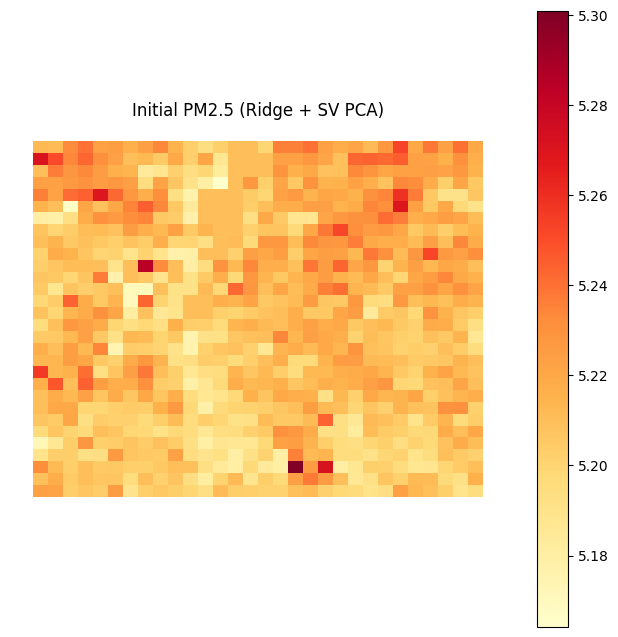

In [92]:
# Predict using PCA components
X_grid = grid_features[predictor_cols].to_numpy(dtype=float)
grid_features["predicted_log_pm25_ridge"] = ridge_predict(ridge_model, X_grid).clip(0, np.log1p(50))
grid_features["predicted_pm25_ridge"] = np.expm1(grid_features["predicted_log_pm25_ridge"]).clip(lower=0.0)
grid_features["clipped_final_pm25"] = grid_features["predicted_pm25_ridge"].clip(lower=0.0, upper=40)

initial_pm25_map = gpd.GeoDataFrame(grid_features, geometry="geometry", crs=base_crs)

fig, ax = plt.subplots(figsize=(8, 8))
initial_pm25_map.plot(column="clipped_final_pm25", cmap="YlOrRd", legend=True, ax=ax)
ax.set_axis_off()
ax.set_title("Initial PM2.5 (Ridge + SV PCA)")
plt.show()


In [93]:
# Compute sensor residuals in log-space
sensor_model_df = sensor_cell_df[["sensor_name", "pm25"] + predictor_cols].dropna().copy()
X_sensor = sensor_model_df[predictor_cols].to_numpy(dtype=float)
sensor_model_df["ridge_pred_log"] = ridge_predict(ridge_model, X_sensor)
sensor_model_df["observed_log_pm25"] = np.log1p(sensor_model_df["pm25"].clip(lower=0.0))
sensor_model_df["residual"] = sensor_model_df["observed_log_pm25"] - sensor_model_df["ridge_pred_log"]

sensors_proj = gdf_sensors.to_crs(initial_pm25_map.crs).copy()
sensors_proj["x"] = sensors_proj.geometry.x
sensors_proj["y"] = sensors_proj.geometry.y

sensor_residuals_df = sensor_model_df.merge(
    sensors_proj[["sensor_name", "x", "y"]], on="sensor_name", how="left"
)
sensor_residuals_df


,sensor_name,pm25,sv_pc1,sv_pc2,ridge_pred_log,observed_log_pm25,residual,x,y
0,Boston Carter Field,10.322884,0.235819,0.516468,1.825267,2.426826,0.601558,234252.312622,898834.637669
1,Boston Gainsborough Parking Garage,16.439812,-0.301737,-0.851378,1.827849,2.858756,1.030907,234191.453996,898960.969606
2,Boston Robinson Hall,0.003135,-0.054277,-1.400990,1.828030,0.003130,-1.824900,234073.213353,898826.532851
3,Boston West Village B,0.884483,0.564962,1.140543,1.823935,0.633653,-1.190281,233591.199929,898653.278770
4,Boston World Series Way,23.751881,0.403463,-0.541109,1.826186,3.208901,1.382716,233795.319059,898775.220621


Residual variogram model:
{'model': 'gaussian', 'nugget': 0.0, 'sill': 2.5721994636174874, 'range': 133.49931965358485, 'score_mse': 3.188811357189303, 'lag_centers': [128.53819628807997, 214.23032714679997, 299.92245800551996, 471.30671972295994, 642.6909814403999], 'experimental_semivariance': [0.09217009657274301, 3.443940966999293, 5.144398927234975, 0.1894528269402057, 2.036091829053689], 'fitted_semivariance': [1.5543371538524082, 2.376347491650504, 2.5556689509856314, 2.572189524188364, 2.5721994633962213]}


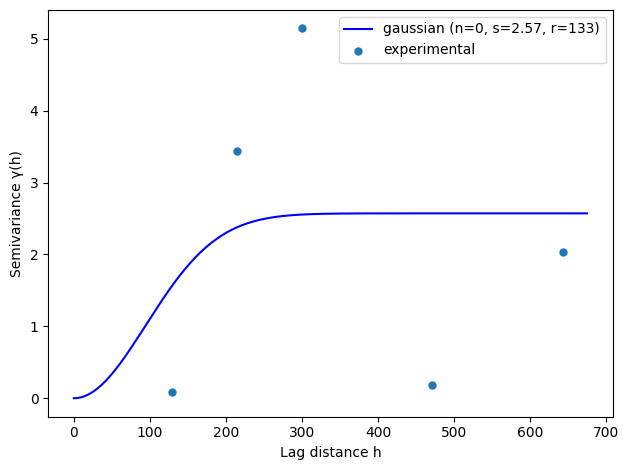

In [94]:
# Fit variogram model on log-space residuals
res_points = list(zip(sensor_residuals_df["x"].to_list(), sensor_residuals_df["y"].to_list()))
res_values = sensor_residuals_df["residual"].to_list()

residual_variogram_model = fit_variogram_model(points=res_points, values=res_values)

print("Residual variogram model:")
print(residual_variogram_model)
plot_variogram_fit(residual_variogram_model)

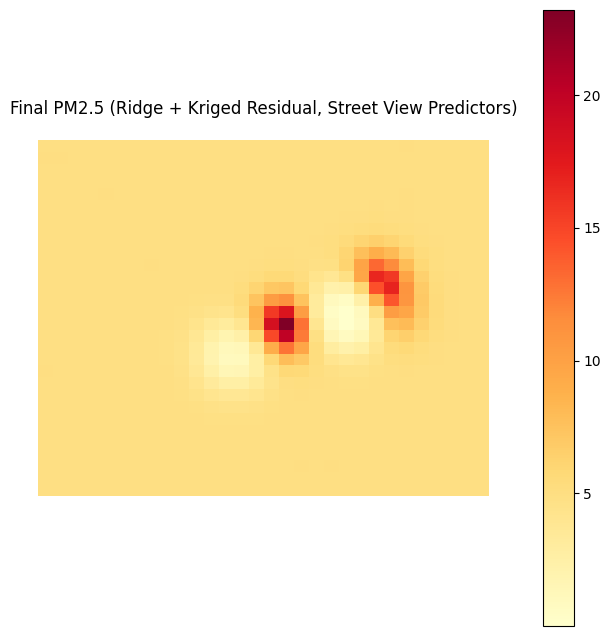

Saved to: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/kriging_street_view/pm25_sv_kriging_grid.geojson


In [95]:
# Krige log-space residuals and produce final PM2.5 map
query_points = [(geom.centroid.x, geom.centroid.y) for geom in initial_pm25_map.geometry]
estimated_residuals = ordinary_kriging_predict(
    points=res_points,
    values=res_values,
    fit=residual_variogram_model,
    query_points=query_points,
)

final_pm25_map = initial_pm25_map.copy()
final_pm25_map["estimated_residual_log"] = estimated_residuals
final_pm25_map["final_log_pm25"] = (
    final_pm25_map["predicted_log_pm25_ridge"] + final_pm25_map["estimated_residual_log"]
).clip(0, np.log1p(50))
final_pm25_map["final_pm25"] = np.expm1(final_pm25_map["final_log_pm25"]).clip(lower=0.0)

fig, ax = plt.subplots(figsize=(8, 8))
final_pm25_map.plot(column="final_pm25", cmap="YlOrRd", legend=True, ax=ax)
ax.set_axis_off()
ax.set_title("Final PM2.5 (Ridge + Kriged Residual, Street View Predictors)")
plt.show()

OUTPUT_PATH = SV_DIR / "pm25_sv_kriging_grid.geojson"
final_pm25_map.to_file(OUTPUT_PATH, driver="GeoJSON")
print(f"Saved to: {OUTPUT_PATH}")